In [ ]:
from google.colab import drive
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Load and normalize the selected features

In [ ]:
# Load the feature datasets
FEATURES_DIR = Path("/content/drive/MyDrive/Formative2 HMM/Features")
train_df = pd.read_csv(FEATURES_DIR / "train_features.csv")
test_df = pd.read_csv(FEATURES_DIR / "test_features.csv")

# Load the selected feature names
with open(FEATURES_DIR / "feature_selection.json", "r") as file:
    selection_config = json.load(file)

SELECTED_FEATURES = selection_config["selected_features"]

# Fit the normalization using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[SELECTED_FEATURES])
X_test = scaler.transform(test_df[SELECTED_FEATURES])

# Validate the normalized feature matrices
assert X_train.shape == (303, len(SELECTED_FEATURES))
assert X_test.shape == (55, len(SELECTED_FEATURES))
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(train_df["recording_id"]).isdisjoint(set(test_df["recording_id"]))

print("HMM FEATURE PREPARATION")
print(f"Selected features: {len(SELECTED_FEATURES)}")
print(f"Training matrix shape: {X_train.shape}")
print(f"Testing matrix shape: {X_test.shape}")
print(f"Training recordings: {train_df['recording_id'].nunique()}")
print(f"Testing recordings: {test_df['recording_id'].nunique()}")
print("\nNORMALIZED TRAINING FEATURES")
display(pd.DataFrame(X_train, columns=SELECTED_FEATURES).head())

HMM FEATURE PREPARATION
Selected features: 6
Training matrix shape: (303, 6)
Testing matrix shape: (55, 6)
Training recordings: 50
Testing recordings: 8

NORMALIZED TRAINING FEATURES


,acc_rms,gyro_rms,acc_xy_corr,acc_dominant_freq,acc_spectral_energy,gyro_spectral_energy
0,0.999336,1.367764,0.518573,0.979247,1.159341,1.285185
1,1.471237,0.970051,0.973699,0.674615,1.632013,0.503346
2,1.786813,1.004598,1.352257,0.979247,2.343173,0.458558
3,1.662366,0.877377,1.436486,0.979247,1.872530,0.487122
4,1.889491,0.568172,1.575736,0.979247,2.885709,-0.076835


## 2. Implement and Train the Hidden Markov Model

We're implementing a **four-state Gaussian HMM with diagonal covariance matrices.**

### 2.A. Reconstruct sequences and initialize the HMM

Although X_train contains 303 rows, those rows belong to 50 independent recordings. We must reconstruct those separate sequences to prevent artificial transitions between recordings.

We'll also initialize the Gaussian emission parameters using the known training labels. Baum-Welch will subsequently refine them using the observation sequences.

In [ ]:
# Define the four hidden states
ACTIVITIES = ["Walking", "Jumping", "Standing", "Still"]
NUM_STATES = len(ACTIVITIES)
NUM_FEATURES = X_train.shape[1]
STATE_TO_INDEX = {activity: index for index, activity in enumerate(ACTIVITIES)}

# Reconstruct independent sequences without mixing recordings
train_metadata = train_df.reset_index(drop=True)
train_groups = list(train_metadata.groupby(["activity", "recording_id"], sort=False))
train_sequences = [X_train[group.index.to_numpy()] for _, group in train_groups]
train_labels = [STATE_TO_INDEX[activity] for (activity, recording_id), group in train_groups]

# Initialize starting state probabilities
pi = np.full(NUM_STATES, 1 / NUM_STATES)

# Initialize a persistence-oriented transition matrix
A = np.full((NUM_STATES, NUM_STATES), 0.02 / (NUM_STATES - 1))
np.fill_diagonal(A, 0.98)

# Initialize Gaussian parameters using training activity labels
means = np.vstack([X_train[train_metadata["activity"] == activity].mean(axis=0) for activity in ACTIVITIES])
variances = np.vstack([np.maximum(X_train[train_metadata["activity"] == activity].var(axis=0), 0.05) for activity in ACTIVITIES])

# Validate the initial model
assert len(train_sequences) == 50
assert sum(len(sequence) for sequence in train_sequences) == 303
assert np.allclose(A.sum(axis=1), 1)
assert np.isfinite(means).all() and np.isfinite(variances).all()

print("HMM INITIALIZATION")
print(f"Hidden states: {ACTIVITIES}")
print(f"Independent training sequences: {len(train_sequences)}")
print(f"Observation dimensions: {NUM_FEATURES}")
print(f"Gaussian means shape: {means.shape}")
print(f"Gaussian variances shape: {variances.shape}")
print("\nINITIAL TRANSITION MATRIX")
display(pd.DataFrame(A, index=ACTIVITIES, columns=ACTIVITIES).round(4))

HMM INITIALIZATION
Hidden states: ['Walking', 'Jumping', 'Standing', 'Still']
Independent training sequences: 50
Observation dimensions: 6
Gaussian means shape: (4, 6)
Gaussian variances shape: (4, 6)

INITIAL TRANSITION MATRIX


,Walking,Jumping,Standing,Still
Walking,0.9800,0.0067,0.0067,0.0067
Jumping,0.0067,0.9800,0.0067,0.0067
Standing,0.0067,0.0067,0.9800,0.0067
Still,0.0067,0.0067,0.0067,0.9800


### 2.B. Implement the HMM algorithms

In [ ]:
# 1. Gaussian emission log-probabilities
def gaussian_log_emissions(X, means, variances):
    differences = X[:, None, :] - means[None, :, :]
    log_density = -0.5 * np.sum(np.log(2 * np.pi * variances)[None, :, :] + differences ** 2 / variances[None, :, :], axis=2)
    return log_density


# 2. Forward-Backward algorithm
def forward_backward(X, pi, A, means, variances):
    log_B = gaussian_log_emissions(X, means, variances)
    log_pi = np.log(np.maximum(pi, 1e-300))
    log_A = np.log(np.maximum(A, 1e-300))

    T = len(X)
    K = len(pi)
    alpha = np.empty((T, K))
    beta = np.empty((T, K))

    # Forward pass
    alpha[0] = log_pi + log_B[0]

    for t in range(1, T):
        alpha[t] = log_B[t] + np.logaddexp.reduce(alpha[t - 1, :, None] + log_A, axis=0)

    log_likelihood = np.logaddexp.reduce(alpha[-1])

    # Backward pass
    beta[-1] = 0.0

    for t in range(T - 2, -1, -1):
        beta[t] = np.logaddexp.reduce(log_A + log_B[t + 1, None, :] + beta[t + 1, None, :], axis=1)

    # State posterior probabilities
    gamma = np.exp(alpha + beta - log_likelihood)

    # Expected transition counts
    transition_counts = np.zeros((K, K))

    for t in range(T - 1):
        log_xi = alpha[t, :, None] + log_A + log_B[t + 1, None, :] + beta[t + 1, None, :] - log_likelihood
        transition_counts += np.exp(log_xi)

    return gamma, transition_counts, log_likelihood


# 3. Total log-likelihood across independent sequences
def total_log_likelihood(sequences, pi, A, means, variances):
    return sum(forward_backward(X, pi, A, means, variances)[2] for X in sequences)


# 4. Baum-Welch training
def baum_welch(sequences, pi, A, means, variances, max_iter=150, tol=1e-4, variance_floor=0.05):
    pi = pi.copy()
    A = A.copy()
    means = means.copy()
    variances = variances.copy()

    K, D = means.shape
    history = [total_log_likelihood(sequences, pi, A, means, variances)]

    for iteration in range(max_iter):
        pi_counts = np.zeros(K)
        A_counts = np.zeros((K, K))
        state_counts = np.zeros(K)
        weighted_sum = np.zeros((K, D))
        weighted_squares = np.zeros((K, D))

        # Expectation step
        for X in sequences:
            gamma, transitions, log_likelihood = forward_backward(X, pi, A, means, variances)

            pi_counts += gamma[0]
            A_counts += transitions
            state_counts += gamma.sum(axis=0)
            weighted_sum += gamma.T @ X
            weighted_squares += gamma.T @ (X ** 2)

        # Maximization step
        pi = pi_counts / pi_counts.sum()
        A = np.maximum(A_counts, 1e-10)
        A = A / A.sum(axis=1, keepdims=True)
        means = weighted_sum / np.maximum(state_counts[:, None], 1e-10)
        variances = np.maximum(weighted_squares / np.maximum(state_counts[:, None], 1e-10) - means ** 2, variance_floor)

        # Convergence monitoring
        current_likelihood = total_log_likelihood(sequences, pi, A, means, variances)
        history.append(current_likelihood)

        if abs(history[-1] - history[-2]) < tol:
            break

    return pi, A, means, variances, np.asarray(history)


# 5. Viterbi decoding
def viterbi(X, pi, A, means, variances):
    log_B = gaussian_log_emissions(X, means, variances)
    log_pi = np.log(np.maximum(pi, 1e-300))
    log_A = np.log(np.maximum(A, 1e-300))

    T = len(X)
    K = len(pi)
    delta = np.empty((T, K))
    backpointers = np.zeros((T, K), dtype=int)

    # Initialization
    delta[0] = log_pi + log_B[0]

    # Recursion
    for t in range(1, T):
        candidates = delta[t - 1, :, None] + log_A
        backpointers[t] = np.argmax(candidates, axis=0)
        delta[t] = log_B[t] + candidates[backpointers[t], np.arange(K)]

    # Backtracking
    states = np.empty(T, dtype=int)
    states[-1] = np.argmax(delta[-1])

    for t in range(T - 2, -1, -1):
        states[t] = backpointers[t + 1, states[t + 1]]

    return states

print("All HMM algorithms implemented successfully.")

All HMM algorithms implemented successfully.


**EXPLANATION: What the algorithms do?**

**Forward-Backward:** Calculates posterior probabilities that each observation was generated by each hidden state, given the entire recording.

**Baum-Welch:** Uses those posterior probabilities to iteratively refine $\pi$, $A$, Gaussian means and variances. We stop when the absolute improvement in log-likelihood falls below $10^{-4}$, with 150 iterations as a safety limit.

**Viterbi:** Finds the single most likely sequence of hidden states, given a recording's feature vectors and the trained HMM.

### 2.C. Train on all 50 recordings and examine convergence

HMM TRAINING RESULTS
Hidden states: 4
Independent training sequences: 50
Feature dimensions: 6
Baum-Welch iterations: 10
Initial log-likelihood: -746.4748
Final log-likelihood: -726.4631
Final likelihood change: 0.00002714
Converged: True
Training window accuracy: 92.74%

LEARNED INITIAL STATE PROBABILITIES


,Activity,Probability
0,Walking,0.2798
1,Jumping,0.2202
2,Standing,0.2614
3,Still,0.2386



LEARNED TRANSITION MATRIX


,Walking,Jumping,Standing,Still
Walking,0.9843,0.0157,0.000,0.000
Jumping,0.0000,1.0000,0.000,0.000
Standing,0.0000,0.0000,0.905,0.095
Still,0.0000,0.0000,0.000,1.000


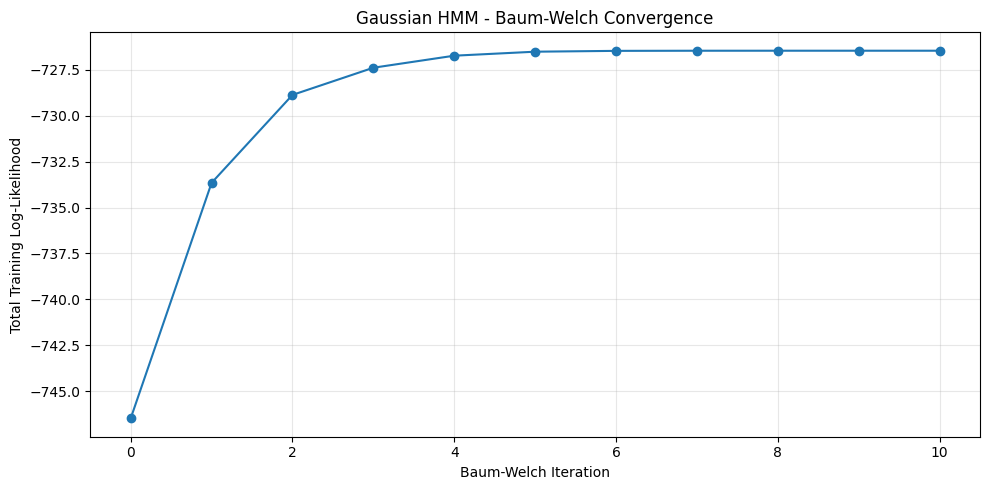

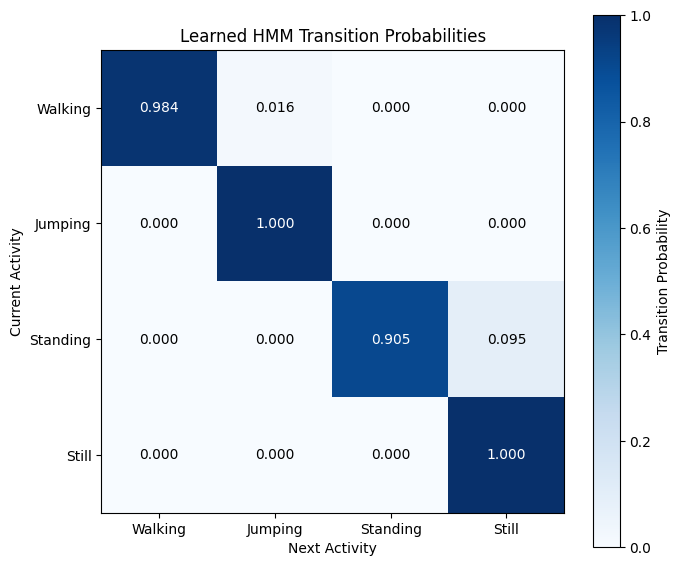


Model saved to: /content/drive/MyDrive/Formative2 HMM/Models/gaussian_hmm_4state.npz
Plots saved to: /content/drive/MyDrive/Formative2 HMM/Plots


In [ ]:
# Train the Gaussian HMM
trained_pi, trained_A, trained_means, trained_variances, likelihood_history = baum_welch(train_sequences, pi, A, means, variances)

# Validate the trained parameters
assert np.isfinite(likelihood_history).all()
assert np.isfinite(trained_means).all() and np.isfinite(trained_variances).all()
assert np.allclose(trained_pi.sum(), 1)
assert np.allclose(trained_A.sum(axis=1), 1)

# Evaluate Viterbi decoding on training sequences
train_predictions = [viterbi(X, trained_pi, trained_A, trained_means, trained_variances) for X in train_sequences]
correct_train_windows = sum(np.sum(prediction == label) for prediction, label in zip(train_predictions, train_labels))
total_train_windows = sum(len(prediction) for prediction in train_predictions)
train_accuracy = correct_train_windows / total_train_windows

# Training summary
print("HMM TRAINING RESULTS")
print(f"Hidden states: {NUM_STATES}")
print(f"Independent training sequences: {len(train_sequences)}")
print(f"Feature dimensions: {NUM_FEATURES}")
print(f"Baum-Welch iterations: {len(likelihood_history) - 1}")
print(f"Initial log-likelihood: {likelihood_history[0]:.4f}")
print(f"Final log-likelihood: {likelihood_history[-1]:.4f}")
print(f"Final likelihood change: {likelihood_history[-1] - likelihood_history[-2]:.8f}")
print(f"Converged: {abs(likelihood_history[-1] - likelihood_history[-2]) < 1e-4}")
print(f"Training window accuracy: {train_accuracy:.2%}")

print("\nLEARNED INITIAL STATE PROBABILITIES")
display(pd.DataFrame({"Activity": ACTIVITIES, "Probability": trained_pi}).round(4))

print("\nLEARNED TRANSITION MATRIX")
display(pd.DataFrame(trained_A, index=ACTIVITIES, columns=ACTIVITIES).round(4))

# Save the trained model
MODEL_DIR = FEATURES_DIR.parent / "Models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
np.savez(MODEL_DIR / "gaussian_hmm_4state.npz", pi=trained_pi, A=trained_A, means=trained_means, variances=trained_variances, activities=np.array(ACTIVITIES), features=np.array(SELECTED_FEATURES), scaler_mean=scaler.mean_, scaler_scale=scaler.scale_, log_likelihood_history=likelihood_history)

# Save convergence plot
PLOTS_DIR = FEATURES_DIR.parent / "Plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.plot(range(len(likelihood_history)), likelihood_history, marker="o")
plt.xlabel("Baum-Welch Iteration")
plt.ylabel("Total Training Log-Likelihood")
plt.title("Gaussian HMM - Baum-Welch Convergence")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "HMM_Baum_Welch_Convergence.png", dpi=300, bbox_inches="tight")
plt.show()

# Save transition matrix heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(trained_A, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_STATES), ACTIVITIES)
ax.set_yticks(range(NUM_STATES), ACTIVITIES)
ax.set_xlabel("Next Activity")
ax.set_ylabel("Current Activity")
ax.set_title("Learned HMM Transition Probabilities")

for i in range(NUM_STATES):
    for j in range(NUM_STATES):
        ax.text(j, i, f"{trained_A[i, j]:.3f}", ha="center", va="center", color="white" if trained_A[i, j] > 0.5 else "black")

fig.colorbar(im, ax=ax, label="Transition Probability")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "HMM_Transition_Matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nModel saved to: {MODEL_DIR / 'gaussian_hmm_4state.npz'}")
print(f"Plots saved to: {PLOTS_DIR}")


## Interpretation of HMM Training Results

### 1. Overview of the Trained Hidden Markov Model

We implemented a four-state Gaussian Hidden Markov Model (HMM) from scratch using NumPy to recognize four human activities: **Walking, Jumping, Standing, and Still**.

The model uses six engineered features extracted from 2-second overlapping sensor windows. These features describe acceleration intensity, rotational movement, cross-axis relationships, and frequency-domain characteristics.

The HMM was trained using the **Baum–Welch algorithm**, while the **Viterbi algorithm** was used to decode the most likely sequences of hidden activity states.

The training configuration and results are summarized below:

| Parameter | Result |
|---|---|
| Hidden states | 4 |
| Observation features | 6 |
| Independent training sequences | 50 |
| Training windows | 303 |
| Baum–Welch iterations | 10 |
| Initial log-likelihood | -746.4748 |
| Final log-likelihood | -726.4631 |
| Final log-likelihood change | 0.00002714 |
| Convergence achieved | True |
| Training window accuracy | 92.74% |

The model successfully completed training, with its log-likelihood increasing and satisfying the predefined convergence criterion.

The training accuracy of **92.74%** indicates that the HMM correctly decoded approximately 281 of the 303 training windows.

However, training accuracy measures performance on data used to estimate the model parameters. It does not establish generalization to unseen recordings.

### 2. Interpretation of the Baum–Welch Convergence Plot

The Baum–Welch convergence plot illustrates how the total training log-likelihood changes over successive training iterations.

The log-likelihood measures how well the HMM explains the observed feature sequences under its current parameters.

Mathematically, the total training log-likelihood is:

$$
\mathcal{L}(\theta) = \sum_{r=1}^{R} \log P(X^{(r)} \mid \theta)
$$

Where:

- $R = 50$ is the number of independent training recordings.
- $X^{(r)}$ represents the sequence of feature vectors from recording $r$.
- $\theta$ represents the HMM parameters: initial probabilities, transition probabilities, Gaussian means, and variances.

**Interpretation of our results:**

The initial log-likelihood was:

$$
\mathcal{L}_{initial} = -746.4748
$$

After training, the final log-likelihood increased to:

$$
\mathcal{L}_{final} = -726.4631
$$

Therefore, the total improvement was:

$$
\Delta \mathcal{L} = -726.4631 - (-746.4748) = 20.0117
$$

This increase indicates that the updated HMM parameters explain the training observations better than the initial parameters, according to the model's likelihood function.

The negative log-likelihood values do not indicate incorrect training. Gaussian HMMs work with continuous probability densities, and the logarithms of those densities can sum to negative values.

**Analysis of the convergence curve:**

- **Iterations 0–3:** The log-likelihood increases rapidly, indicating substantial improvements during the initial Baum–Welch updates.
- **Iterations 4–5:** The rate of improvement decreases as the model approaches a stable solution.
- **Iterations 6–10:** The curve becomes almost horizontal, indicating that additional updates produce very small changes.

This pattern is consistent with convergence of the Expectation-Maximization algorithm.

#### Convergence Criterion

The implementation uses the following stopping criterion:

$$
|\mathcal{L}_{k} - \mathcal{L}_{k-1}| < \epsilon
$$

Where:

- $\mathcal{L}_{k}$ is the total log-likelihood at iteration $k$.
- $\mathcal{L}_{k-1}$ is the total log-likelihood at the previous iteration.
- $\epsilon = 10^{-4}$ is the convergence tolerance.

The final change was:

$$
\Delta \mathcal{L}_{final} = 0.00002714
$$

Since:

$$
0.00002714 < 0.0001
$$

The convergence criterion was satisfied after **10 iterations**, well before reaching the maximum limit of 150 iterations.

**Conclusion:** The convergence plot provides evidence that Baum–Welch successfully optimized the HMM parameters and reached a numerically stable solution under the selected tolerance.

However, convergence does not guarantee that the model has found the globally optimal parameters or that it will classify unseen data accurately.

### 3. Interpretation of the Learned Initial State Probabilities

The initial state probability vector, denoted by $\pi$, represents the probability that an observation sequence begins in each hidden activity state.

The learned probabilities are:

| Activity | Initial Probability |
|---|---:|
| Walking | 0.2798 |
| Jumping | 0.2202 |
| Standing | 0.2614 |
| Still | 0.2386 |

These values sum to 1, as required for a valid probability distribution.

**Interpretation:**

- **Walking (27.98%):** Has the highest learned probability of being the initial hidden state.
- **Jumping (22.02%):** Has the lowest initial probability.
- **Standing (26.14%):** Has a relatively high initial probability.
- **Still (23.86%):** Has a probability comparable to the other activities.

The probabilities are reasonably balanced, meaning no activity has been assigned a negligible starting probability.

These values are model estimates derived from the training observations. They do not represent the actual real-world frequency with which people begin each activity.

Since our dataset contains separate recordings of individual activities, the learned starting probabilities mainly reflect the structure and feature distributions of our collected data.

### 4. Interpretation of the Learned Transition Probability Matrix

The transition matrix, denoted by $A$, describes the probability of moving from one hidden state to another between consecutive observation windows.

Each entry is defined as:

$$
A_{ij} = P(Z_{t+1}=j \mid Z_t=i)
$$

Where:

- $Z_t$ is the hidden activity state at time step $t$.
- $Z_{t+1}$ is the hidden activity state at the next time step.
- $A_{ij}$ is the probability of transitioning from state $i$ to state $j$.

Our learned transition matrix is:

| Current / Next State | Walking | Jumping | Standing | Still |
|---|---:|---:|---:|---:|
| Walking | 0.9843 | 0.0157 | ≈0 | ≈0 |
| Jumping | ≈0 | 1.0000 | ≈0 | ≈0 |
| Standing | ≈0 | ≈0 | 0.9050 | 0.0950 |
| Still | ≈0 | ≈0 | ≈0 | 1.0000 |

#### 4.1. Walking Transitions

The probability of remaining in Walking is:

$$
P(Walking \rightarrow Walking) = 0.9843
$$

This corresponds to **98.43%**, indicating that the model strongly favors remaining in the Walking state between consecutive windows.

The probability of transitioning from Walking to Jumping is approximately **1.57%**.

The remaining transitions have probabilities close to zero.

#### 4.2. Jumping Transitions

The probability of remaining in Jumping is approximately:

$$
P(Jumping \rightarrow Jumping) \approx 1.00
$$

This indicates extremely strong state persistence.

Once the model enters Jumping, it is highly likely to remain in that state under the learned transition distribution.

This is consistent with our training recordings, which contain repeated jumping movements rather than deliberate transitions between different activities.

#### 4.3. Standing Transitions

The probability of remaining in Standing is:

$$
P(Standing \rightarrow Standing) = 0.905
$$

The model also estimates:

$$
P(Standing \rightarrow Still) = 0.095
$$

Therefore, the model assigns approximately **90.5% probability to remaining Standing** and **9.5% probability to transitioning to Still**.

This may reflect similarities between the extracted features of Standing and Still. Both activities involve relatively little movement compared with Walking and Jumping.

Nevertheless, the transition should not be interpreted as direct evidence that people physically transition from Standing to Still with a probability of 9.5%.

#### 4.4. Still Transitions

The probability of remaining in Still is approximately:

$$
P(Still \rightarrow Still) \approx 1.00
$$

The model therefore strongly favors continued inactivity once the Still state has been identified.

This is compatible with the recorded Still activity, during which the phone remained motionless on a flat surface.

### 5. Interpretation of the Transition Probability Heatmap

The transition probability heatmap visualizes the learned transition matrix.

- **Rows** represent the current hidden activity.
- **Columns** represent the next hidden activity.
- **Darker blue cells** represent higher transition probabilities.
- **Lighter cells** represent probabilities closer to zero.

The most prominent pattern is the **dark main diagonal**, indicating that self-transitions dominate the learned model.

This suggests that the HMM has learned strong temporal persistence within individual activities.

The two noticeable off-diagonal transitions are:

1. **Walking → Jumping:** Approximately 1.57%.
2. **Standing → Still:** Approximately 9.50%.

Most other off-diagonal probabilities are extremely small. Values displayed as 0.000 are rounded and do not necessarily equal exactly zero.

#### Why Does the Model Favor Self-Transitions?

Our training dataset consists of 50 separate recordings, each containing one activity performed continuously for approximately 5–10 seconds.

Consequently, the data provides strong evidence of activity persistence but limited direct evidence of transitions between different activities.

Additionally, the transition matrix was initialized with a 98% self-transition probability, reinforcing this persistence-oriented starting assumption.

Baum–Welch then refined the transition probabilities using the observed feature sequences.

**Important limitation:** The learned transition matrix describes the behavior of our fitted HMM, not necessarily realistic physical transitions between human activities.

For example, probabilities close to 1 may make the model slow to recognize an activity change during longer continuous recordings.

A future improvement would involve collecting recordings containing deliberate transitions between Walking, Jumping, Standing, and Still.

### 6. Interpretation of Gaussian Emission Parameters

Our model uses multivariate Gaussian emission distributions to represent the six selected features for each hidden activity.

For state $k$, the emission density is:

$$
P(X_t \mid Z_t=k) = \mathcal{N}(X_t;\mu_k,\Sigma_k)
$$

Where:

- $X_t$ is the six-dimensional observation vector.
- $\mu_k$ is the mean feature vector for activity $k$.
- $\Sigma_k$ is the covariance matrix for activity $k$.

We use **diagonal covariance matrices**, meaning each state has a separate variance for each of the six features, while cross-feature covariance terms are not modeled explicitly.

#### Gaussian Means

The mean describes the typical value of each normalized feature within a hidden activity state.

For example, the fitted mean of acceleration RMS can help distinguish relatively high-intensity activities such as Jumping from low-intensity activities such as Still.

Different states can therefore have different centers in the six-dimensional feature space.

#### Gaussian Variances

Variance measures the spread of observed feature values around a state's mean.

For a particular feature:

$$
\sigma^2 = E[(X-\mu)^2]
$$

A smaller variance means that feature values tend to be concentrated near the mean, while a larger variance indicates greater variability.

In our activity recognition problem:

- **Small variance:** May indicate relatively consistent sensor behavior within an activity.
- **Large variance:** May indicate greater changes in movement intensity or rotation across windows.

However, the actual learned variance values must be inspected before determining which activities have the largest or smallest variance for each feature.

#### Variance Floor

During training, we applied a minimum variance of:

$$
\sigma^2_{min} = 0.05
$$

This variance floor prevents the model from producing extremely narrow Gaussian distributions or dividing by values close to zero.

It improves numerical stability, particularly when a feature varies very little within an activity.

The value 0.05 is a regularization parameter applied in standardized feature space, not a measured sensor variance.

**Conclusion:** Gaussian means and variances determine how likely each feature vector is under each hidden activity state. Their separation and spread influence the quality of the HMM's predictions.

### 7. Interpretation of Training Accuracy

The trained HMM achieved:

$$
Accuracy_{train} = 92.74\%
$$

The training accuracy is calculated as:

$$
Accuracy = \frac{\text{Correctly Predicted Windows}}{\text{Total Windows}} \times 100
$$

With 303 training windows, approximately 281 were correctly decoded.

This suggests that the trained HMM can distinguish most activity patterns within the training dataset.

However, the result should be interpreted carefully for three reasons:

1. **Training-set evaluation:** The same recordings were used to estimate the model parameters, so the accuracy may be optimistic.
2. **Overlapping windows:** Consecutive windows share 50% of their samples and are therefore correlated rather than independent.
3. **Label-informed initialization:** Gaussian means and variances were initialized using known training activity labels before Baum–Welch refinement.

Therefore, the training accuracy is evidence that the model fits the training dataset reasonably well, but unseen-data evaluation is necessary to assess generalization.

### 8. Transition Matrix vs. Confusion Matrix

The transition probability matrix and confusion matrix serve different purposes.

**Transition Probability Matrix:**

Describes how the HMM models transitions between hidden activity states across consecutive observation windows.

For example, Walking → Walking = 0.9843 indicates a high modeled probability of remaining in the Walking state.

**Confusion Matrix:**

Evaluates classification performance by comparing the predicted activity labels against the actual activity labels.

In our planned confusion matrix:

- Rows will represent actual activities.
- Columns will represent predicted activities.
- Diagonal cells will represent correct predictions.
- Off-diagonal cells will represent misclassifications.

Unlike the transition matrix, the confusion matrix directly reveals which activities are correctly identified and which are confused with one another.

The confusion matrix will be calculated from the eight unseen test recordings during the evaluation stage. Therefore, no test confusion-matrix results are reported at this point.

### 9. Overall Interpretation and Conclusion

The training results demonstrate that our four-state Gaussian Hidden Markov Model was successfully implemented and optimized using the Baum–Welch algorithm.

The log-likelihood improved from **-746.4748 to -726.4631**, and the algorithm satisfied the convergence tolerance after **10 iterations**, indicating stable parameter estimation under the selected model configuration.

The **92.74% training accuracy** suggests that the six engineered features contain useful information for distinguishing Walking, Jumping, Standing, and Still.

The learned transition matrix is dominated by self-transitions, which is consistent with the structure of our dataset, where each recording contains one sustained activity.

Nevertheless, the dominance of self-transitions limits how confidently we can interpret the model's ability to represent realistic changes between activities.

Furthermore, successful convergence and high training accuracy do not guarantee strong generalization.

The next stage is therefore to evaluate the trained model on **eight unseen recordings containing 55 feature windows**, calculating accuracy, sensitivity, specificity, and a confusion matrix, alongside visualization of the decoded activity sequences and Gaussian emission distributions.

## 3. Evaluate the HMM on Unseen Data

We will evaluate the model using all eight test recordings at once, without retraining or changing any model parameters.
We'll then calculate both window-level and recording-level accuracy, along with sensitivity, specificity, and a confusion matrix.

### 3.A. Decode all eight test recordings and calculate evaluation metrics

In [ ]:
# Reconstruct independent test sequences
test_metadata = test_df.reset_index(drop=True)
test_groups = list(test_metadata.groupby(["activity", "recording_id"], sort=False))

test_sequences = [X_test[group.index.to_numpy()] for _, group in test_groups]
test_labels = [STATE_TO_INDEX[activity] for (activity, recording_id), group in test_groups]

# Decode all eight unseen recordings
test_predictions = [viterbi(X, trained_pi, trained_A, trained_means, trained_variances) for X in test_sequences]

# Collect window-level predictions and recording-level predictions
y_true = np.concatenate([np.full(len(prediction), label) for prediction, label in zip(test_predictions, test_labels)])
y_pred = np.concatenate(test_predictions)

recording_rows = []

for ((activity, recording_id), group), prediction, true_label in zip(test_groups, test_predictions, test_labels):
    predicted_label = int(np.argmax(np.bincount(prediction, minlength=NUM_STATES)))
    recording_rows.append({"recording_id": recording_id, "actual_activity": activity, "predicted_activity": ACTIVITIES[predicted_label],
                           "windows": len(prediction), "correct": predicted_label == true_label})

recording_results_df = pd.DataFrame(recording_rows)

# Overall evaluation metrics
window_accuracy = accuracy_score(y_true, y_pred)
recording_accuracy = recording_results_df["correct"].mean()
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_STATES))

# Calculate per-activity sensitivity, specificity and one-vs-rest accuracy
metrics_rows = []

for i, activity in enumerate(ACTIVITIES):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    class_accuracy = (tp + tn) / cm.sum()

    metrics_rows.append({"Activity": activity, "Test recordings": int((recording_results_df["actual_activity"] == activity).sum()),
                         "Test windows": int(cm[i, :].sum()), "Sensitivity": sensitivity, "Specificity": specificity, "One-vs-rest accuracy": class_accuracy})

metrics_df = pd.DataFrame(metrics_rows)

print("UNSEEN TEST EVALUATION")
print(f"Test recordings: {len(test_sequences)}")
print(f"Test windows: {len(y_true)}")
print(f"Window-level accuracy: {window_accuracy:.2%}")
print(f"Recording-level accuracy: {recording_accuracy:.2%}")

print("\nPER-ACTIVITY PERFORMANCE")
display(metrics_df.round(4))

print("\nRESULTS FOR ALL EIGHT RECORDINGS")
display(recording_results_df)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_true, y_pred, labels=np.arange(NUM_STATES), target_names=ACTIVITIES, zero_division=0, digits=4))

# Save evaluation results
recording_results_df.to_csv(MODEL_DIR / "test_recording_predictions.csv", index=False)
metrics_df.to_csv(MODEL_DIR / "test_activity_metrics.csv", index=False)

assert len(test_sequences) == 8
assert len(y_true) == 55
assert cm.sum() == 55
assert np.isfinite(metrics_df[["Sensitivity", "Specificity", "One-vs-rest accuracy"]].to_numpy()).all()

print("\nEvaluation results saved successfully.")

UNSEEN TEST EVALUATION
Test recordings: 8
Test windows: 55
Window-level accuracy: 85.45%
Recording-level accuracy: 87.50%

PER-ACTIVITY PERFORMANCE


,Activity,Test recordings,Test windows,Sensitivity,Specificity,One-vs-rest accuracy
0,Walking,2,13,0.5385,0.9524,0.8545
1,Jumping,2,15,0.8667,1.0000,0.9636
2,Standing,2,13,1.0000,0.8571,0.8909
3,Still,2,14,1.0000,1.0000,1.0000



RESULTS FOR ALL EIGHT RECORDINGS


,recording_id,actual_activity,predicted_activity,windows,correct
0,Jumping_test_01,Jumping,Jumping,7,True
1,Jumping_test_02,Jumping,Jumping,8,True
2,Standing_test_01,Standing,Standing,7,True
3,Standing_test_02,Standing,Standing,6,True
4,Still_testing_01,Still,Still,7,True
5,Still_testing_02,Still,Still,7,True
6,Walking_test_01,Walking,Walking,7,True
7,Walking_test_02,Walking,Standing,6,False



CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Walking     0.7778    0.5385    0.6364        13
     Jumping     1.0000    0.8667    0.9286        15
    Standing     0.6842    1.0000    0.8125        13
       Still     1.0000    1.0000    1.0000        14

    accuracy                         0.8545        55
   macro avg     0.8655    0.8513    0.8444        55
weighted avg     0.8728    0.8545    0.8503        55


Evaluation results saved successfully.


### 3.B. Generate all required evaluation visualizations

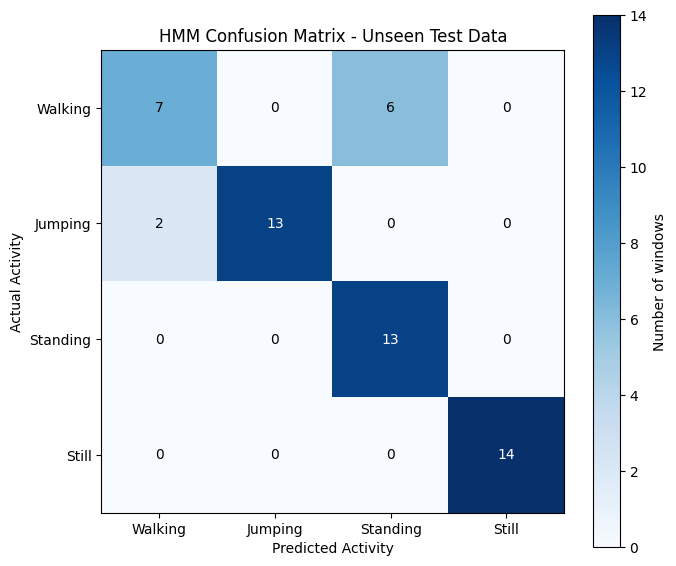

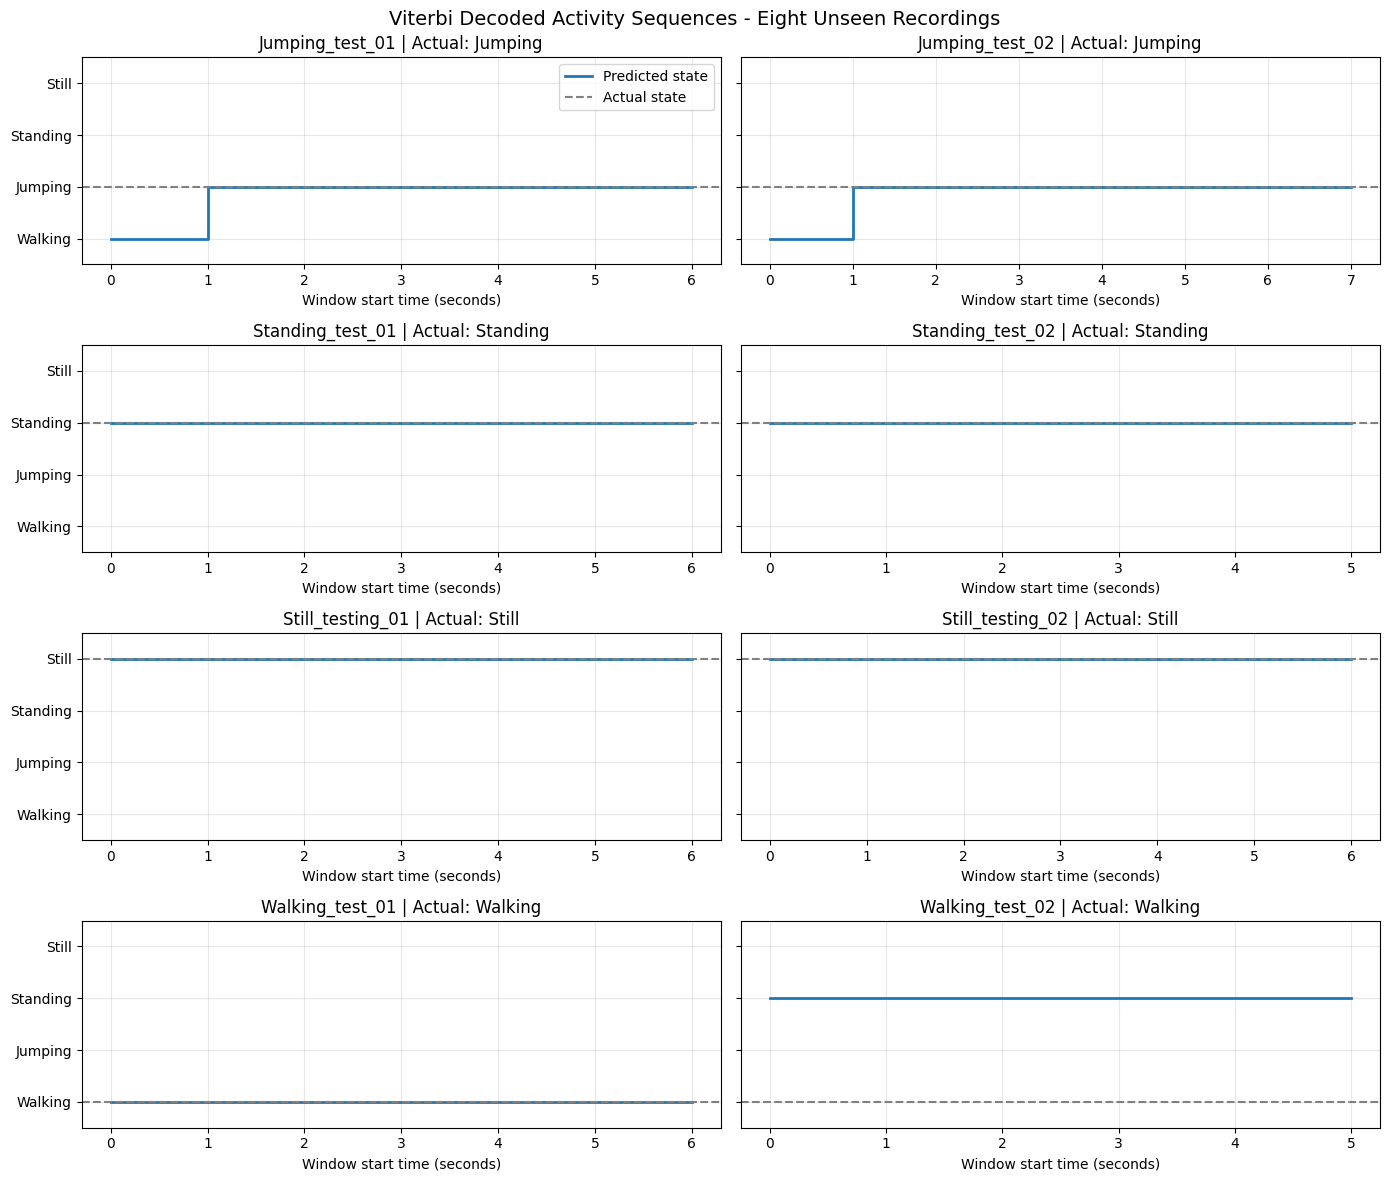

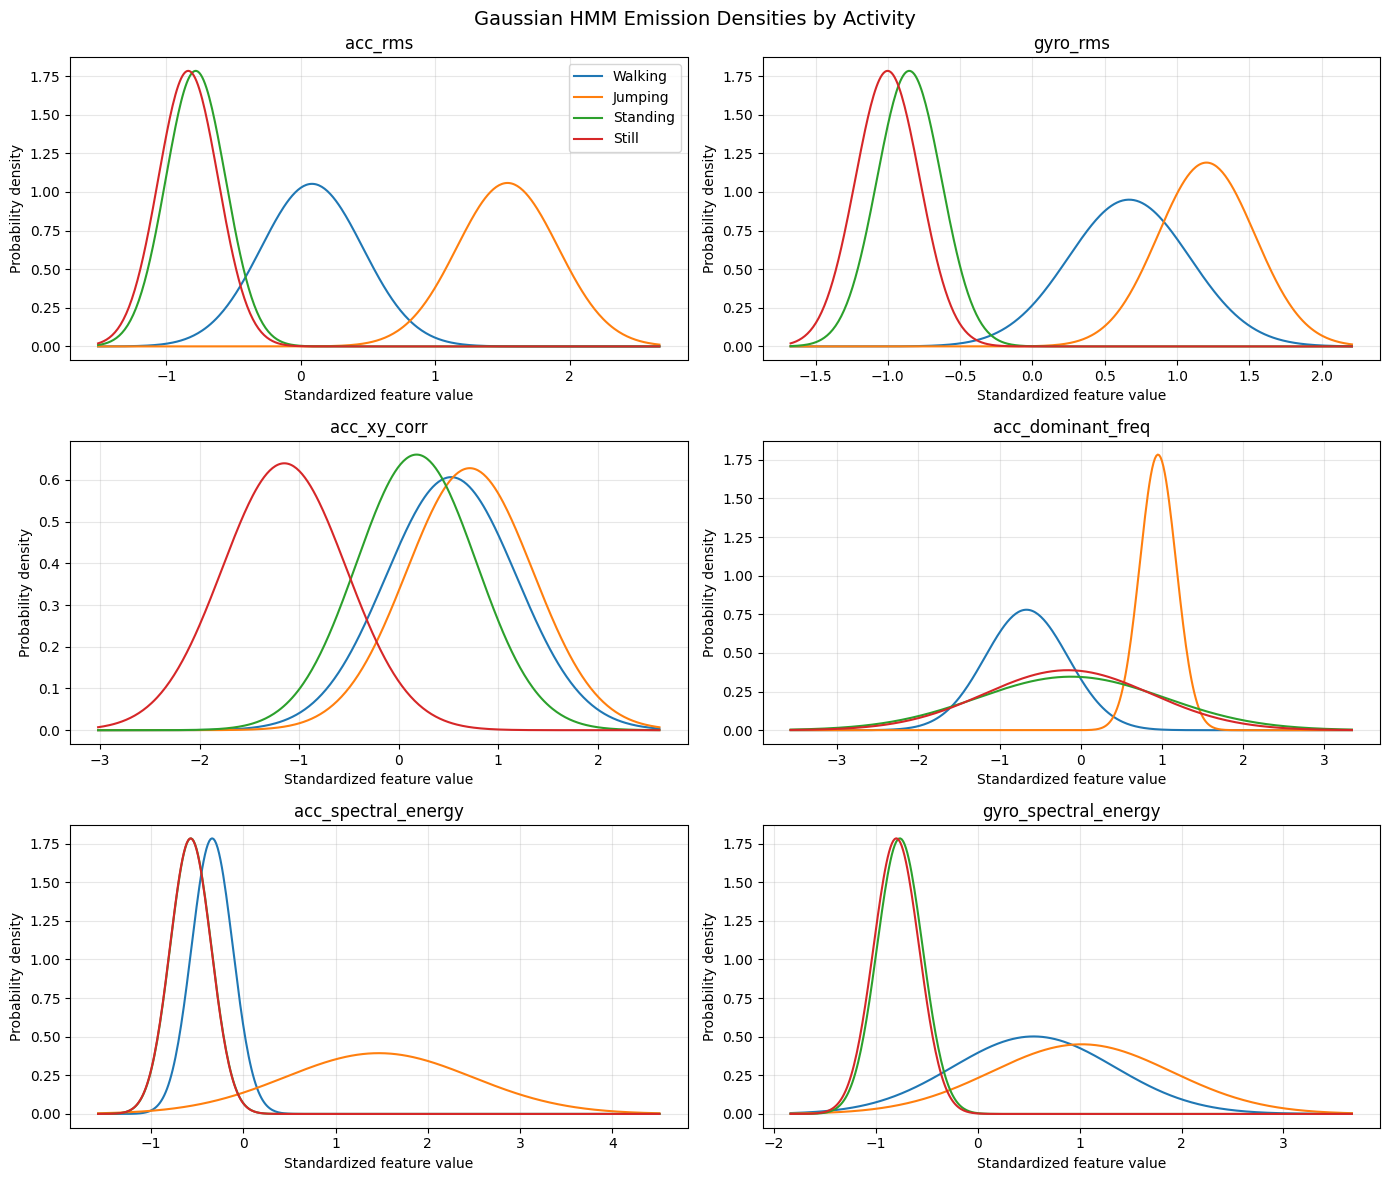

All three evaluation figures saved to: /content/drive/MyDrive/Formative2 HMM/Plots


In [ ]:
# 1. Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_STATES), ACTIVITIES)
ax.set_yticks(range(NUM_STATES), ACTIVITIES)
ax.set_xlabel("Predicted Activity")
ax.set_ylabel("Actual Activity")
ax.set_title("HMM Confusion Matrix - Unseen Test Data")

for i in range(NUM_STATES):
    for j in range(NUM_STATES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

fig.colorbar(im, ax=ax, label="Number of windows")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "HMM_Test_Confusion_Matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. Viterbi decoded state sequences
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharey=True)

for ax, ((activity, recording_id), group), prediction, true_label in zip(axes.flat, test_groups, test_predictions, test_labels):
    times = group["window_start_s"].to_numpy()

    ax.step(times, prediction, where="post", label="Predicted state", linewidth=2)
    ax.axhline(true_label, color="gray", linestyle="--", label="Actual state")
    ax.set_title(f"{recording_id} | Actual: {activity}")
    ax.set_yticks(range(NUM_STATES), ACTIVITIES)
    ax.set_ylim(-0.5, NUM_STATES - 0.5)
    ax.set_xlabel("Window start time (seconds)")
    ax.grid(True, alpha=0.3)

axes.flat[0].legend(loc="best")
fig.suptitle("Viterbi Decoded Activity Sequences - Eight Unseen Recordings", fontsize=14)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "HMM_Viterbi_Test_Sequences.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Gaussian emission probability densities for the selected features
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for j, feature in enumerate(SELECTED_FEATURES):
    ax = axes.flat[j]

    state_stds = np.sqrt(trained_variances[:, j])
    lower = min(np.quantile(X_train[:, j], 0.01), np.min(trained_means[:, j] - 3 * state_stds))
    upper = max(np.quantile(X_train[:, j], 0.99), np.max(trained_means[:, j] + 3 * state_stds))
    x_values = np.linspace(lower, upper, 400)

    for i, activity in enumerate(ACTIVITIES):
        mu = trained_means[i, j]
        sigma = state_stds[i]
        density = np.exp(-0.5 * ((x_values - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
        ax.plot(x_values, density, label=activity)

    ax.set_title(feature)
    ax.set_xlabel("Standardized feature value")
    ax.set_ylabel("Probability density")
    ax.grid(True, alpha=0.3)

axes.flat[0].legend()
fig.suptitle("Gaussian HMM Emission Densities by Activity", fontsize=14)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "HMM_Gaussian_Emission_Densities.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"All three evaluation figures saved to: {PLOTS_DIR}")


## Interpretation of HMM Evaluation on Unseen Test Data

### 1. Overview of the Evaluation Results

After training our four-state Gaussian Hidden Markov Model (HMM), we evaluated its ability to recognize **Walking, Jumping, Standing, and Still** using previously unseen sensor recordings.

The evaluation dataset consisted of **8 independent test recordings**, with 2 recordings per activity. These recordings were not used to fit the feature normalization parameters or train the HMM.

Each recording was segmented into 2-second windows with 50% overlap, producing 55 testing windows. The trained HMM used the Viterbi algorithm to decode the most likely activity sequence for each recording.

The evaluation results were:

| Evaluation Metric | Result |
|---|---:|
| Unseen test recordings | 8 |
| Total test windows | 55 |
| Correctly classified windows | 47 |
| Misclassified windows | 8 |
| Window-level accuracy | 85.45% |
| Recording-level accuracy | 87.50% |
| Macro precision | 0.8655 |
| Macro recall | 0.8513 |
| Macro F1-score | 0.8444 |
| Weighted F1-score | 0.8503 |

These results indicate that the trained HMM can recognize most of the activity patterns present in the unseen recordings.

However, the model performs differently across the four activities, with **Still and Standing showing stronger sensitivity than Walking**.

### 2. Window-Level and Recording-Level Accuracy

#### 2.1. Window-Level Accuracy

Window-level accuracy measures the proportion of individual feature windows correctly classified by the HMM.

It is calculated as:

$$
Accuracy = \frac{\text{Correct Predictions}}{\text{Total Predictions}} \times 100
$$

For our evaluation:

$$
Accuracy_{window} = \frac{47}{55} \times 100 = 85.45\%
$$

This means that the HMM correctly classified **47 out of 55 unseen feature windows**.

The remaining eight windows were incorrectly classified.

Although this is an encouraging result, the windows were generated using 50% overlap. Consequently, adjacent windows share sensor measurements and cannot be considered statistically independent test samples.

#### 2.2. Recording-Level Accuracy

Recording-level accuracy evaluates the model's ability to classify an entire recording instead of individual windows.

We determined the predicted activity for each recording using a majority vote over its Viterbi-decoded window labels.

The results were:

$$
Accuracy_{recording} = \frac{7}{8} \times 100 = 87.50\%
$$

The model correctly classified **seven out of eight unseen recordings**.

The only incorrectly classified recording was **Walking_test_02**, which was predicted as Standing.

Recording-level accuracy is useful because it better reflects our practical objective of identifying the activity performed during a complete recording.

However, the estimate is based on only eight independent test recordings. Therefore, additional unseen recordings would be needed to obtain a more reliable estimate of generalization performance.

### 3. Comparison Between Training and Testing Accuracy

The HMM achieved:

| Dataset | Accuracy |
|---|---:|
| Training windows | 92.74% |
| Testing windows | 85.45% |

The difference is:

$$
\Delta Accuracy = 92.74\% - 85.45\% = 7.29 \text{ percentage points}
$$

The testing accuracy is approximately **7.29 percentage points lower** than the training accuracy.

This reduction is expected to some extent because the model was optimized using training observations and had not previously encountered the testing recordings.

The difference suggests that the model does not generalize equally well to all unseen movement patterns.

Nevertheless, testing accuracy remains relatively high, indicating that the selected features contain useful information beyond the training recordings.

This difference alone does not establish severe overfitting. The small number of independent test recordings and differences between recording sessions may also contribute to the observed performance gap.

### 4. Interpretation of the Confusion Matrix

The confusion matrix compares the actual activity labels with the activities predicted by the HMM.

- **Rows** represent the actual activities.
- **Columns** represent the predicted activities.
- **Diagonal values** represent correctly classified windows.
- **Off-diagonal values** represent classification errors.

Our confusion matrix is:

| Actual / Predicted | Walking | Jumping | Standing | Still |
|---|---:|---:|---:|---:|
| Walking | 7 | 0 | 6 | 0 |
| Jumping | 2 | 13 | 0 | 0 |
| Standing | 0 | 0 | 13 | 0 |
| Still | 0 | 0 | 0 | 14 |

The diagonal contains:

$$
7 + 13 + 13 + 14 = 47
$$

These are the correctly classified windows.

The off-diagonal contains eight errors, distributed across two activity pairs.

#### 4.1. Walking

Out of 13 actual Walking windows:

- **7 windows** were correctly classified as Walking.
- **6 windows** were incorrectly classified as Standing.
- No Walking windows were classified as Jumping or Still.

Walking therefore achieved the lowest recall among the four activities.

The six Walking-to-Standing errors all came from the second Walking test recording.

This indicates that the model had difficulty distinguishing the movement characteristics of that particular recording from the learned Standing feature distribution.

Possible explanations include differences in movement intensity, phone orientation, recording conditions, or the extracted feature patterns. However, these explanations remain hypotheses until the recording itself is examined.

#### 4.2. Jumping

Out of 15 actual Jumping windows:

- **13 windows** were correctly classified as Jumping.
- **2 windows** were incorrectly classified as Walking.
- None were classified as Standing or Still.

The two errors occurred at the beginning of the two Jumping test recordings.

Despite these initial errors, the HMM subsequently identified Jumping correctly for the remaining windows of both recordings.

This suggests that the model can recognize sustained jumping patterns but may initially confuse some jumping observations with walking.

#### 4.3. Standing

All **13 Standing windows** were correctly classified.

This demonstrates excellent sensitivity for Standing on the available test data.

However, the model also incorrectly predicted Standing for six Walking windows.

Therefore, although the model successfully recognized all actual Standing windows, not every Standing prediction was correct.

This distinction explains why Standing has perfect sensitivity but lower precision and specificity.

#### 4.4. Still

All **14 Still windows** were correctly classified.

Furthermore, no windows from other activities were incorrectly classified as Still.

Therefore, Still achieved perfect precision, recall, and specificity on this particular test set.

This suggests that the extracted features effectively distinguish the recorded motionless-phone condition from the other activities.

However, these perfect results should not be interpreted as guaranteed performance under different devices, users, environments, or recording conditions.

### 5. Sensitivity, Specificity, Precision, and F1-Score

To understand the performance of each activity, we calculated several classification metrics.

#### Sensitivity (Recall)

Sensitivity measures the proportion of actual positive observations correctly identified.

$$
Sensitivity = \frac{TP}{TP + FN}
$$

Where:

- $TP$ = True Positives
- $FN$ = False Negatives

A higher sensitivity indicates that the model misses fewer examples of the activity.

#### Specificity

Specificity measures the proportion of observations belonging to other activities that are correctly rejected.

$$
Specificity = \frac{TN}{TN + FP}
$$

Where:

- $TN$ = True Negatives
- $FP$ = False Positives

A higher specificity indicates that the model is less likely to incorrectly assign an activity label to observations from other activities.

#### Precision

Precision measures the proportion of predictions assigned to an activity that are correct.

$$
Precision = \frac{TP}{TP + FP}
$$

#### F1-Score

The F1-score is the harmonic mean of precision and recall.

$$
F_1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

It is useful when we want to assess both missed activities and incorrect activity predictions.

#### Per-Activity Results

| Activity | Test Windows | Sensitivity | Specificity | Precision | F1-Score |
|---|---:|---:|---:|---:|---:|
| Walking | 13 | 53.85% | 95.24% | 77.78% | 0.6364 |
| Jumping | 15 | 86.67% | 100.00% | 100.00% | 0.9286 |
| Standing | 13 | 100.00% | 85.71% | 68.42% | 0.8125 |
| Still | 14 | 100.00% | 100.00% | 100.00% | 1.0000 |

**Walking:** Has the weakest sensitivity at 53.85%. This means that nearly half of the actual Walking windows were missed, primarily because they were classified as Standing.

**Jumping:** Achieved 86.67% sensitivity and 100% specificity. The model recognized most Jumping windows and did not incorrectly classify any other activity as Jumping.

**Standing:** Achieved 100% sensitivity but only 85.71% specificity. Although all actual Standing windows were recognized, six Walking windows were incorrectly assigned to Standing.

**Still:** Achieved 100% sensitivity, specificity, precision, and F1-score on the available test recordings.

The main classification challenge is therefore **distinguishing Walking from Standing in one of the unseen Walking recordings**.

### 6. Interpretation of the Viterbi Decoded Activity Sequences

The Viterbi sequence visualization shows how the HMM classified successive feature windows within each unseen recording.

Each subplot contains:

- A **blue line** representing the predicted hidden activity state.
- A **gray dashed line** representing the actual activity.
- The horizontal axis showing the start time of each window.
- The vertical axis showing the four possible activity states.

A blue line overlapping the gray dashed line indicates correct predictions.

#### 6.1. Jumping_test_01 and Jumping_test_02

Both Jumping recordings display a similar pattern.

The HMM initially classified the first window as Walking before switching to Jumping at approximately 1 second.

After this change, the predicted state remained Jumping throughout the remaining windows.

This explains the two Jumping-to-Walking errors in the confusion matrix.

Importantly, this predicted change does **not** represent a confirmed physical transition from Walking to Jumping. Both recordings were labeled Jumping throughout.

Instead, it represents the HMM correcting an initial classification error after incorporating additional observations.

#### 6.2. Standing_test_01 and Standing_test_02

For both Standing recordings, the predicted blue line overlaps the actual Standing reference line across all windows.

This indicates that the HMM consistently recognized the Standing activity throughout both recordings.

No incorrect state transitions were predicted.

#### 6.3. Still_testing_01 and Still_testing_02

Both Still recordings were classified correctly throughout their observation sequences.

The predicted state remained Still across every window.

This is consistent with the low acceleration and rotational activity expected when the phone is placed on a flat surface without intentional movement.

#### 6.4. Walking_test_01

The first Walking recording was classified correctly across all seven windows.

The predicted state remained Walking throughout the recording.

This demonstrates that the model can recognize sustained Walking when its feature patterns resemble those learned during training.

#### 6.5. Walking_test_02

The second Walking recording produced the most significant evaluation error.

All six windows were classified as Standing, even though the actual activity was Walking.

The predicted blue line remains at Standing throughout the recording, while the actual reference line remains at Walking.

This confirms that the model did not merely misclassify an isolated window. Instead, it consistently assigned the entire recording to the wrong activity.

The strong self-transition probabilities learned during training may have contributed to the persistence of the incorrect prediction.

However, the plot alone cannot establish whether the primary cause was the transition model, the Gaussian emission distributions, or differences in the recorded movement.

**Conclusion:** The Viterbi plots show that the HMM generally produces stable activity sequences, but they also reveal two important limitations: occasional incorrect initial predictions and the possibility of maintaining an incorrect state throughout an entire recording.

### 7. Interpretation of the Gaussian Emission Density Plots

The Gaussian emission density plots illustrate how the trained HMM represents the distributions of our six selected features across the four hidden states.

Each graph displays:

- The standardized feature value on the horizontal axis.
- The Gaussian probability density on the vertical axis.
- Four curves representing Walking, Jumping, Standing, and Still.

The curves are derived from the HMM's learned Gaussian means and variances.

They do not directly represent the testing accuracy, nor are their vertical values probabilities of belonging to an activity.

A feature is generally more useful for distinguishing two activities when their fitted distributions are well separated.

#### 7.1. Acceleration RMS (`acc_rms`)

The acceleration RMS distributions show a strong separation between movement-intensive and relatively stationary activities.

- **Jumping:** Has the highest mean acceleration RMS.
- **Walking:** Has a lower mean than Jumping but remains clearly above the stationary activities.
- **Standing and Still:** Have similarly low acceleration RMS distributions with substantial overlap.

This demonstrates why acceleration RMS is particularly valuable for distinguishing Jumping and Walking from Standing and Still.

However, acceleration RMS alone provides limited separation between the two stationary activities.

#### 7.2. Gyroscope RMS (`gyro_rms`)

Gyroscope RMS measures the overall intensity of rotational movement.

The fitted distributions show:

- High rotational intensity for Jumping.
- Moderate rotational intensity for Walking.
- Low rotational intensity for Standing and Still.

The Jumping and Walking distributions overlap somewhat, while Standing and Still are much closer to each other.

This feature therefore provides useful information for separating active movement from relative inactivity.

However, it is less useful for distinguishing Standing from Still on its own.

#### 7.3. Acceleration X–Y Correlation (`acc_xy_corr`)

This feature measures the relationship between acceleration along the X and Y axes.

The emission curves show that:

- Walking and Jumping have relatively high positive standardized mean values.
- Standing has a lower mean.
- Still has a substantially lower mean than the other activities.

Unlike acceleration RMS and gyroscope RMS, this feature provides noticeable separation between Standing and Still.

This helps explain why combining movement-intensity features with cross-axis relationships is more informative than relying on acceleration magnitude alone.

Nevertheless, this feature is sensitive to phone orientation, so its behavior may change if the device is held differently.

#### 7.4. Acceleration Dominant Frequency (`acc_dominant_freq`)

The dominant acceleration frequency represents the strongest nonzero frequency component in each window.

The Gaussian curves show a narrow, concentrated distribution for Jumping and a distinct distribution for Walking.

Standing and Still exhibit much broader, overlapping distributions.

This suggests that the dominant acceleration frequency is particularly useful for distinguishing rhythmic movement activities.

However, in low-motion activities, dominant frequency can be influenced by small sensor fluctuations rather than meaningful physical movement.

Therefore, dominant frequency should be interpreted together with motion-intensity and spectral-energy features.

#### 7.5. Acceleration Spectral Energy (`acc_spectral_energy`)

Acceleration spectral energy summarizes the strength of acceleration fluctuations within the selected frequency range.

The fitted distributions show:

- Jumping has a substantially higher mean spectral energy and a broader distribution.
- Walking has lower spectral energy than Jumping.
- Standing and Still have low spectral energy with strongly overlapping distributions.

This makes acceleration spectral energy useful for identifying intensive rhythmic movement, particularly Jumping.

However, it contributes relatively little separation between Standing and Still by itself.

#### 7.6. Gyroscope Spectral Energy (`gyro_spectral_energy`)

Gyroscope spectral energy represents the strength of rotational fluctuations within the selected frequency band.

The distributions show higher spectral energy for Walking and Jumping, with noticeable overlap between these two activities.

Standing and Still have lower values and almost identical distributions.

This feature is therefore useful for distinguishing active movement from stationary behavior but provides limited information for separating the two stationary activities.

#### 7.7. Overall Interpretation of Emission Distributions

The six emission plots indicate that different features contribute complementary information.

| Feature | Main Distinguishing Contribution |
|---|---|
| Acceleration RMS | Jumping and Walking versus stationary activities |
| Gyroscope RMS | Rotational intensity across activities |
| Acceleration X–Y correlation | Additional separation of Still from other activities |
| Acceleration dominant frequency | Rhythmic differences, particularly Jumping versus Walking |
| Acceleration spectral energy | Stronger movement fluctuations, especially Jumping |
| Gyroscope spectral energy | Rotational fluctuations during active movement |

No single feature perfectly distinguishes all four activities.

Instead, the HMM combines evidence from all six features and uses temporal transition probabilities to decode the most likely sequence of states.

The model uses diagonal Gaussian covariance matrices, which do not explicitly represent correlations between different features. This is a simplifying assumption and may limit performance when features remain statistically dependent.

Additionally, several emission variances reach the minimum value of 0.05 imposed during training. This prevents numerical instability but also constrains how narrowly the model can represent some feature distributions.

### 8. Which Activities Were Easiest and Hardest to Distinguish?

Based on the unseen-data confusion matrix and classification metrics, the activity recognition performance can be summarized as follows.

**Still — Easiest to Recognize**

Still achieved perfect scores across the available testing windows.

The model correctly recognized all 14 Still windows and did not incorrectly assign Still to any other activity.

**Jumping — Strong Performance**

Jumping achieved high sensitivity and perfect precision.

The model correctly classified 13 of 15 Jumping windows, with only the first window of each recording incorrectly classified as Walking.

**Standing — High Recall but Lower Precision**

Standing achieved perfect sensitivity because all actual Standing windows were correctly recognized.

However, its precision was lower because six Walking windows were incorrectly classified as Standing.

**Walking — Hardest to Recognize**

Walking achieved the lowest sensitivity and F1-score.

The model correctly recognized the first Walking test recording but misclassified the entire second recording as Standing.

Therefore, **Walking was the least reliably recognized activity in our unseen test dataset**.

These findings are specific to the available recordings and should not be generalized to all possible walking conditions or phone placements.

### 9. Limitations of the Evaluation

Although the evaluation results are encouraging, several limitations must be acknowledged.

**1. Limited independent test recordings**

The evaluation contains only eight independently collected recordings, with two recordings per activity.

This limits the precision of our performance estimates.

**2. Correlated overlapping windows**

The 55 testing windows are not independent because consecutive windows share 50% of their sensor measurements.

Window-level performance should therefore be interpreted alongside recording-level accuracy.

**3. Limited observed activity transitions**

Each recording contains one sustained activity.

Consequently, the evaluation does not directly test how well the HMM handles real transitions between different activities during continuous monitoring.

**4. Strong self-transition probabilities**

The learned transition matrix strongly favors remaining in the same state.

While this helps maintain stable predictions, it may also cause an incorrect classification to persist across multiple windows.

**5. Feature and emission-model limitations**

The model uses six engineered features with diagonal Gaussian emission distributions.

Some features overlap substantially across activities, and real feature distributions may not be perfectly Gaussian.

These assumptions may limit classification performance for unusual movement patterns.

**6. Limited generalization evidence**

The results demonstrate performance on our specific unseen recordings.

They do not establish how well the model would perform for different participants, smartphone models, device placements, or environments.

### 10. Overall Evaluation and Conclusion

The Gaussian HMM demonstrated promising performance in recognizing human activities from smartphone accelerometer and gyroscope data.

Using six engineered features and Viterbi decoding, the model achieved:

- **85.45% window-level accuracy**
- **87.50% recording-level accuracy**
- **0.8444 macro F1-score**
- **47 correctly classified windows out of 55**
- **7 correctly classified recordings out of 8**

The confusion matrix demonstrates that Still was recognized perfectly, while Jumping and Standing also showed strong sensitivity.

However, Walking was more difficult to distinguish, particularly in `Walking_test_02`, which was consistently misclassified as Standing.

The Viterbi sequence plots confirm that the model generally produces stable activity predictions but may maintain an incorrect state throughout an entire recording.

The Gaussian emission density plots further demonstrate that movement intensity and frequency-domain characteristics help distinguish active from stationary activities, while some features remain less effective at separating similar activity patterns.

Overall, the results suggest that our feature-engineered Gaussian HMM can recognize meaningful human activity patterns on unseen recordings, but its performance remains sensitive to differences in movement characteristics and the limitations of our relatively small dataset.

**Future improvements** could include collecting additional recordings with different movement intensities, evaluating alternative window sizes and feature combinations using training-only validation, testing more flexible emission distributions, and recording continuous sequences containing genuine transitions between activities.

These improvements could help address the observed Walking-to-Standing confusion and provide stronger evidence of model generalization.

## 4. Investigating Walking-to-Standing Misclassification

We'll investigate why `Walking_test_02` was classified entirely as Standing, while `Walking_test_01` was correctly classified as Walking.


RECORDING: Walking_test_01
Number of windows: 7
Predicted states: ['Walking', 'Walking', 'Walking', 'Walking', 'Walking', 'Walking', 'Walking']
Mean emission log-likelihood advantage (Standing - Walking): -19.7685
Total emission advantage (Standing - Walking): -138.3795
Initial/transition advantage (Standing - Walking): -0.5721
Complete constant-path score advantage (Standing - Walking): -138.9515
Constant-path preference: Walking

RECORDING: Walking_test_02
Number of windows: 6
Predicted states: ['Standing', 'Standing', 'Standing', 'Standing', 'Standing', 'Standing']
Mean emission log-likelihood advantage (Standing - Walking): 0.7758
Total emission advantage (Standing - Walking): 4.6548
Initial/transition advantage (Standing - Walking): -0.4881
Complete constant-path score advantage (Standing - Walking): 4.1666
Constant-path preference: Standing

FEATURE COMPARISON (STANDARDIZED VALUES)


,Feature,Train Walking Mean,Train Standing Mean,Walking_test_01,Walking_test_02
0,acc_rms,0.0700,-0.7799,-0.0911,-0.1870
1,gyro_rms,0.6551,-0.8579,0.2277,-0.1029
2,acc_xy_corr,0.5398,-0.1783,-0.6406,-0.8278
3,acc_dominant_freq,-0.6739,-0.2969,1.0228,1.2839
4,acc_spectral_energy,-0.3409,-0.5685,-0.5033,-0.5097
5,gyro_spectral_energy,0.5166,-0.7694,0.0393,-0.3728



FEATURE CONTRIBUTIONS TO STANDING VS WALKING


recording_id,Walking_test_01,Walking_test_02
feature,,
acc_dominant_freq,6.2521,5.7283
acc_rms,-4.1780,-2.7758
acc_spectral_energy,0.2341,0.2639
acc_xy_corr,0.7139,0.7691
gyro_rms,-11.2975,-3.4038
gyro_spectral_energy,-11.4930,0.1941



INTERPRETATION: Positive contribution favors Standing; negative contribution favors Walking.


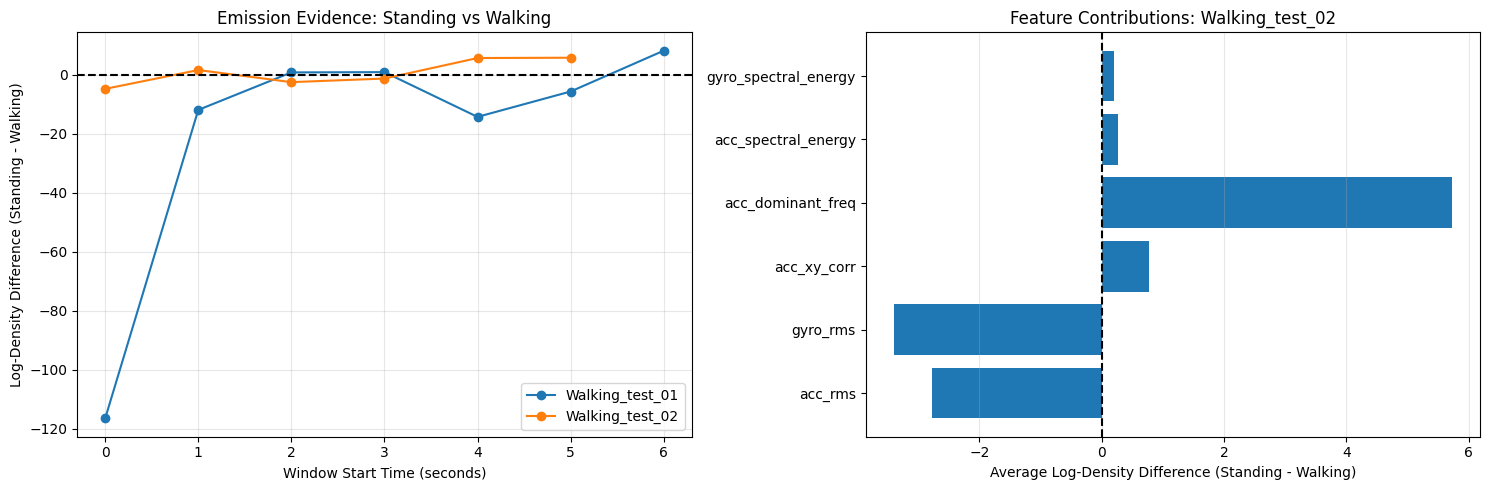


Diagnostic analysis completed. Model parameters were not modified.


In [ ]:
# Identify the two unseen Walking recordings
walking_cases = {}

for ((activity, recording_id), group), X, prediction in zip(test_groups, test_sequences, test_predictions):
    if activity == "Walking":
        walking_cases[recording_id] = {"X": X, "prediction": prediction, "times": group["window_start_s"].to_numpy()}

assert len(walking_cases) == 2, "Expected exactly two Walking test recordings"

walking_idx = STATE_TO_INDEX["Walking"]
standing_idx = STATE_TO_INDEX["Standing"]

# Calculate each feature's contribution to the Gaussian emission likelihood
def feature_log_density(X, state):
    mu = trained_means[state]
    var = trained_variances[state]
    return -0.5 * (np.log(2 * np.pi * var) + (X - mu) ** 2 / var)

# Compare test recordings to the learned training distributions
train_walking = X_train[train_df["activity"].to_numpy() == "Walking"]
train_standing = X_train[train_df["activity"].to_numpy() == "Standing"]

comparison = pd.DataFrame({"Feature": SELECTED_FEATURES, "Train Walking Mean": train_walking.mean(axis=0), "Train Standing Mean": train_standing.mean(axis=0)})

diagnostic_rows = []

for recording_id, case in walking_cases.items():
    X = case["X"]
    predictions = case["prediction"]
    walking_log = feature_log_density(X, walking_idx)
    standing_log = feature_log_density(X, standing_idx)
    feature_margin = (standing_log - walking_log).mean(axis=0)
    emission_margin = (standing_log - walking_log).sum()
    T = len(X)

    # Compare the scores of two constant-state paths
    transition_margin = np.log(trained_pi[standing_idx] / trained_pi[walking_idx]) + (T - 1) * np.log(trained_A[standing_idx, standing_idx] / trained_A[walking_idx, walking_idx])
    total_margin = emission_margin + transition_margin

    comparison[recording_id] = X.mean(axis=0)

    for feature, contribution in zip(SELECTED_FEATURES, feature_margin):
        diagnostic_rows.append({"recording_id": recording_id, "feature": feature, "standing_minus_walking_log_density": contribution})

    print(f"\n{'=' * 60}")
    print(f"RECORDING: {recording_id}")
    print(f"Number of windows: {T}")
    print(f"Predicted states: {[ACTIVITIES[i] for i in predictions]}")
    print(f"Mean emission log-likelihood advantage (Standing - Walking): {emission_margin / T:.4f}")
    print(f"Total emission advantage (Standing - Walking): {emission_margin:.4f}")
    print(f"Initial/transition advantage (Standing - Walking): {transition_margin:.4f}")
    print(f"Complete constant-path score advantage (Standing - Walking): {total_margin:.4f}")
    print(f"Constant-path preference: {'Standing' if total_margin > 0 else 'Walking'}")

# Feature comparison table
print("\nFEATURE COMPARISON (STANDARDIZED VALUES)")
display(comparison.round(4))

# Feature-level diagnostic evidence
diagnostic_df = pd.DataFrame(diagnostic_rows)

print("\nFEATURE CONTRIBUTIONS TO STANDING VS WALKING")
display(diagnostic_df.pivot(index="feature", columns="recording_id", values="standing_minus_walking_log_density").round(4))

print("\nINTERPRETATION: Positive contribution favors Standing; negative contribution favors Walking.")

# Create diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for recording_id, case in walking_cases.items():
    X = case["X"]
    walking_log = feature_log_density(X, walking_idx).sum(axis=1)
    standing_log = feature_log_density(X, standing_idx).sum(axis=1)
    axes[0].plot(case["times"], standing_log - walking_log, marker="o", label=recording_id)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Emission Evidence: Standing vs Walking")
axes[0].set_xlabel("Window Start Time (seconds)")
axes[0].set_ylabel("Log-Density Difference (Standing - Walking)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

problem_recording = next(name for name in walking_cases if name.endswith("_02"))
problem_features = diagnostic_df[diagnostic_df["recording_id"] == problem_recording]

axes[1].barh(problem_features["feature"], problem_features["standing_minus_walking_log_density"])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title(f"Feature Contributions: {problem_recording}")
axes[1].set_xlabel("Average Log-Density Difference (Standing - Walking)")
axes[1].grid(True, alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "HMM_Walking_Misclassification_Analysis.png", dpi=300, bbox_inches="tight")
plt.show()

# Save diagnostic tables
comparison.to_csv(MODEL_DIR / "walking_feature_comparison.csv", index=False)
diagnostic_df.to_csv(MODEL_DIR / "walking_feature_contributions.csv", index=False)

print("\nDiagnostic analysis completed. Model parameters were not modified.")


## Interpretation of Walking Misclassification Analysis

### Investigation of Walking_test_02

To investigate why `Walking_test_02` was incorrectly classified as Standing, we compared its six standardized features with the HMM's learned Walking and Standing Gaussian emission distributions. We also examined the contribution of initial and transition probabilities.

**1. Comparison of the Two Walking Recordings**

`Walking_test_01` was correctly classified as Walking across all seven windows, with a total emission log-likelihood difference (Standing − Walking) of **−138.3795**, strongly favoring Walking.

In contrast, `Walking_test_02` was classified as Standing across all six windows. Its total emission log-likelihood difference was **+4.6548**, indicating that its feature observations were collectively more likely under the learned Standing emission distribution than under Walking.

**2. Feature-Level Explanation**

The feature contribution analysis identified the following main factors for `Walking_test_02`:

| Feature | Average Contribution | Interpretation |
|---|---:|---|
| Acceleration dominant frequency | +5.7283 | Strongly favors Standing |
| Gyroscope RMS | −3.4038 | Favors Walking |
| Acceleration RMS | −2.7758 | Favors Walking |
| Acceleration X–Y correlation | +0.7691 | Slightly favors Standing |

The **acceleration dominant frequency** was the strongest contributor to the incorrect prediction. Its positive log-density advantage outweighed the negative contributions from acceleration RMS and gyroscope RMS, which supported the correct Walking classification.

Furthermore, gyroscope spectral energy, which strongly favored Walking in `Walking_test_01` (−11.4930), provided almost no discrimination in `Walking_test_02` (+0.1941).

This indicates that the second recording exhibited a different combination of frequency and rotational characteristics from the correctly classified recording.

**3. Interpretation of the Diagnostic Plots**

The left-hand plot shows that `Walking_test_01` predominantly produced negative emission log-density differences, strongly supporting Walking. By comparison, `Walking_test_02` produced values closer to zero, with positive values in several windows, indicating weaker and occasionally Standing-favoring evidence.

The right-hand plot confirms that acceleration dominant frequency provided the largest evidence in favor of Standing, while acceleration RMS and gyroscope RMS provided evidence against it.

**4. Influence of Transition Probabilities**

For `Walking_test_02`, the initial-state and self-transition contribution was **−0.4881**, slightly favoring Walking.

However, the total emission advantage of **+4.6548** outweighed this contribution, resulting in a complete constant-path score difference of **+4.1666** in favor of Standing.

Therefore, the incorrect prediction was primarily driven by the learned **Gaussian emission distributions**, rather than by an initial or transition-probability preference for Standing.

The strong self-transition probabilities may nevertheless have helped maintain the incorrect state throughout the recording.

### Conclusion

The misclassification of `Walking_test_02` resulted mainly from its extracted frequency-domain characteristics being more compatible with the learned Standing distribution, despite its acceleration and rotational intensity features supporting Walking.

This highlights a limitation of the current six-feature Gaussian HMM: unusual feature combinations can cause the model to favor an incorrect activity, particularly when some Gaussian emission distributions are relatively narrow.

Potential improvements include evaluating alternative frequency-domain features, reviewing feature redundancy, and collecting more diverse Walking recordings. Such improvements should be assessed using training-only validation rather than modifying the model based on the held-out test results.

**!!Importantly, this investigation was performed after evaluation, and no model parameters were modified.**